# 2. Cobertura de skeletons RAW/TANH

Cada AST sorteada tem probabilidade $p=0,5$ de passar por `product_lags` antes da expansão ordenada. O encoder e o alvo do decoder usam a mesma AST escolhida. Comparamos a prior de 1–6 operações com peso proporcional a $e^{0,4(n-1)}$ e probabilidades locais fixas com a amostragem uniforme das ASTs admissíveis contadas combinatoriamente. A proteção seletiva é uma construção do projeto inspirada nas condições de Shao e Wu (2007, Theorem 5.1).


In [1]:
from pathlib import Path
import sys
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'pyproject.toml').exists())
sys.path.insert(0,str(ROOT/'src'))
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from tsfmxai.representations import Add,Multiply,Parameter,Lag,Tanh,MechanismBinding,canonicalize_polynomial,format_canonical_polynomial,format_monomial,walk
from tsfmxai.generators import saturate_product_lags,RandomTreeConfig,sample_random_mechanism,derive_sample_seed,CombinatorialTreeConfig,CombinatorialTreeSampler
from tsfmxai.generators.random_expression import SampledMechanism
from tsfmxai.symbolic_regression.canonical_data import CanonicalCodec,select_canonical_mechanism
pd.set_option('display.max_colwidth',120)

from collections import Counter
from dataclasses import replace
SEED=20261101; N=20000; checkpoints=(100,1000,5000,10000,20000)
weights=np.exp(.4*np.arange(6));weights/=weights.sum()
display(pd.DataFrame({'Operações':range(1,7),'Probabilidade':weights}))


,Operações,Probabilidade
0,1,0.049069
1,2,0.073202
2,3,0.109205
3,4,0.162914
4,5,0.243039
5,6,0.362572


A prior mantém probabilidade positiva para árvores pequenas e favorece árvores com mais operações. Todos os sorteios usam seeds derivadas por índice.

In [2]:
def collect(method):
    counts=Counter();terms={d:set() for d in range(5)}
    lags=Counter();factors=Counter();fail=0;prefix=[];selected_count=0;activated_count=0
    rng=np.random.default_rng(SEED)
    config=RandomTreeConfig(minimum_operators=1,maximum_operators=6,num_series=1,
                            minimum_lag=1,maximum_lag=6,parameter_probability=.4,lag_probability=.6)
    sampler=CombinatorialTreeSampler(CombinatorialTreeConfig(minimum_operators=1,
                            maximum_operators=6,num_series=1,minimum_lag=1,maximum_lag=6,max_degree=4))
    for i in range(N):
        seed=derive_sample_seed(SEED,i)
        if method=='Prior exponencial fixa':
            n=int(rng.choice(np.arange(1,7),p=weights))
            sample=sample_random_mechanism(replace(config,minimum_operators=n,maximum_operators=n),seed=seed)
        else: sample=sampler.sample(seed=seed,sample_index=i)
        mechanism,selected=select_canonical_mechanism(sample,probability=.5,
            root_seed=SEED,sample_index=i)
        selected_count+=selected
        activated_count+=int(any(isinstance(node,Tanh) for node in walk(mechanism.expression)))
        try: poly=canonicalize_polynomial(mechanism.expression,mechanism.binding)
        except ValueError:fail+=1;continue
        skeleton=poly.skeleton;counts[skeleton]+=1
        for term in skeleton:
            terms[len(term)].add(term)
            for atom in term:
                lags[atom[1]]+=1
                factors['TANH' if len(atom)==3 else 'RAW']+=1
        if i+1 in checkpoints:prefix.append((method,i+1,len(counts),sum(counts.values()),fail))
    return counts,terms,lags,factors,fail,prefix,selected_count,activated_count
results={method:collect(method) for method in ('Prior exponencial fixa','ASTs uniformes')}
prefix=pd.DataFrame([r for v in results.values() for r in v[5]],
                    columns=['Método','Sorteios','Skeletons distintos','Aceitos','Rejeitados'])
display(prefix)


,Método,Sorteios,Skeletons distintos,Aceitos,Rejeitados
0,Prior exponencial fixa,100,88,99,1
1,Prior exponencial fixa,1000,618,994,6
2,Prior exponencial fixa,5000,2525,4969,31
3,Prior exponencial fixa,10000,4530,9937,63
4,Prior exponencial fixa,20000,7969,19868,132
5,ASTs uniformes,100,100,100,0
6,ASTs uniformes,1000,984,1000,0
7,ASTs uniformes,5000,4795,5000,0
8,ASTs uniformes,10000,9380,10000,0
9,ASTs uniformes,20000,18330,20000,0


A tabela de prefixos conta skeletons distintos e rejeições por grau no mesmo fluxo de sorteios de cada método.

In [3]:
summary=[]
for method,(counts,terms,lags,factors,fail,_,selected_count,activated_count) in results.items():
    n=sum(counts.values());p=np.array(list(counts.values()))/n
    summary.append({'Método':method,'Aceitos':n,'Rejeitados':fail,'Skeletons distintos':len(counts),
      'Top 15 (%)':100*sum(v for _,v in counts.most_common(15))/n,
      'Diversidade efetiva':float(np.exp(-(p*np.log(p)).sum())),
      'Termos grau 4 distintos':len(terms[4]),
      'RAW (ocorrências)':factors['RAW'],'TANH (ocorrências)':factors['TANH'],
      'Proteção selecionada':selected_count,'TANH inserido':activated_count})
display(pd.DataFrame(summary))


,Método,Aceitos,Rejeitados,Skeletons distintos,Top 15 (%),Diversidade efetiva,Termos grau 4 distintos,RAW (ocorrências),TANH (ocorrências),Proteção selecionada,TANH inserido
0,Prior exponencial fixa,19868,132,7969,17.857862,1856.601990,226,54015,28072,10027,5695
1,ASTs uniformes,20000,0,18330,1.285000,16785.627652,252,96402,77498,10027,9504


Diversidade efetiva é a exponencial da entropia das frequências. RAW e TANH contam aparições nos termos, inclusive repetidas, não séries diferentes.

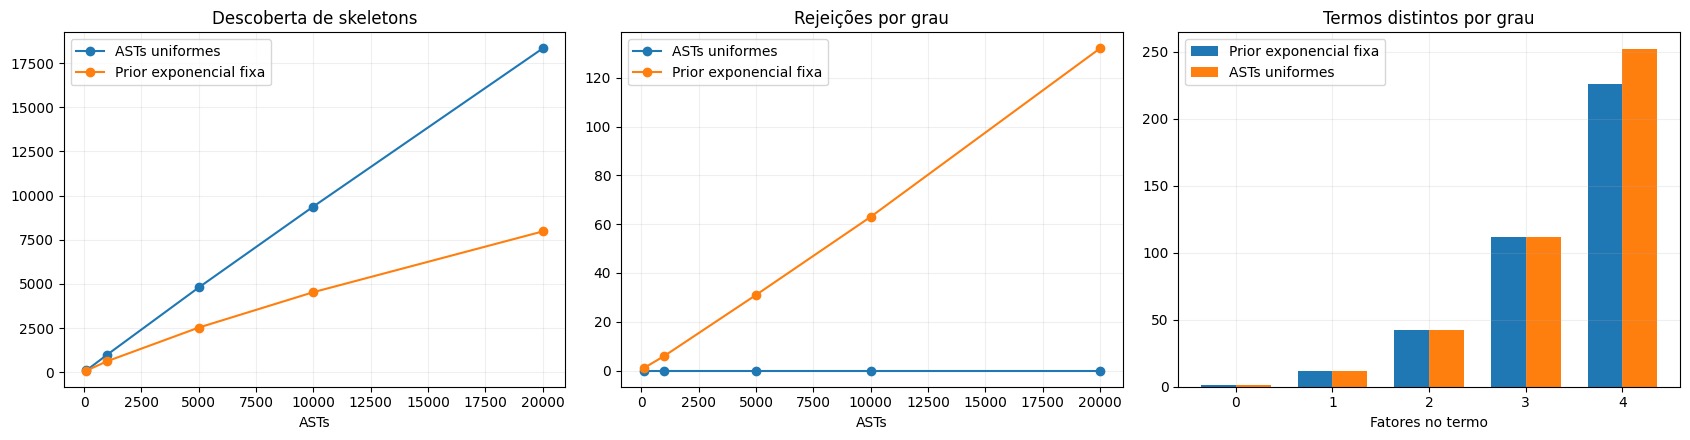

In [4]:
fig,axes=plt.subplots(1,3,figsize=(17,4.5))
for method,part in prefix.groupby('Método'):
    axes[0].plot(part['Sorteios'],part['Skeletons distintos'],marker='o',label=method)
    axes[1].plot(part['Sorteios'],part['Rejeitados'],marker='o',label=method)
for k,(method,r) in enumerate(results.items()):
    axes[2].bar(np.arange(5)+(.18 if k else -.18),
                [len(r[1][d]) for d in range(5)],width=.36,label=method)
for ax in axes:ax.legend();ax.grid(alpha=.2)
axes[0].set(title='Descoberta de skeletons',xlabel='ASTs')
axes[1].set(title='Rejeições por grau',xlabel='ASTs')
axes[2].set(title='Termos distintos por grau',xlabel='Fatores no termo')
plt.tight_layout();plt.show()


Os gráficos distinguem variedade do skeleton completo, rejeições do contrato de grau e cobertura marginal de termos.

In [5]:
rows=[]
for method,r in results.items():
    for rank,(skeleton,count) in enumerate(r[0].most_common(12),1):
        formula=' + '.join(format_monomial(term) for term in skeleton) or '0'
        rows.append((method,rank,formula,count))
display(pd.DataFrame(rows,columns=['Método','Posição','Skeleton sem coeficientes','Ocorrências']))
display(pd.DataFrame([(method,lag,r[2][lag]) for method,r in results.items() for lag in range(1,7)],
                    columns=['Método','Lag','Ocorrências nos termos']))


,Método,Posição,Skeleton sem coeficientes,Ocorrências
0,Prior exponencial fixa,1,1 + s_0[t-4],349
1,Prior exponencial fixa,2,1 + s_0[t-6],347
2,Prior exponencial fixa,3,1 + s_0[t-2],335
3,Prior exponencial fixa,4,1 + s_0[t-3],333
4,Prior exponencial fixa,5,1 + s_0[t-5],333
5,Prior exponencial fixa,6,1 + s_0[t-1],319
6,Prior exponencial fixa,7,1 + s_0[t-1] + s_0[t-3],179
7,Prior exponencial fixa,8,1 + s_0[t-4] + s_0[t-5],176
8,Prior exponencial fixa,9,1 + s_0[t-1] + s_0[t-6],175
9,Prior exponencial fixa,10,1 + s_0[t-1] + s_0[t-5],170


,Método,Lag,Ocorrências nos termos
0,Prior exponencial fixa,1,13833
1,Prior exponencial fixa,2,13582
2,Prior exponencial fixa,3,13583
3,Prior exponencial fixa,4,13456
4,Prior exponencial fixa,5,13789
5,Prior exponencial fixa,6,13844
6,ASTs uniformes,1,28991
7,ASTs uniformes,2,29185
8,ASTs uniformes,3,28836
9,ASTs uniformes,4,29225


As fórmulas deixam legível quais skeletons se repetem. `tanh(s_j[t-l])` é um fator TANH e `s_j[t-l]` é RAW. A tabela de lags conta aparições nos termos, não skeletons contendo cada lag.

## Registro do experimento

**Pergunta:** qual a cobertura empírica de skeletons RAW/TANH? **Configuração:** 20.000 ASTs por método, uma série, lags 1–6, 1–6 operações, grau máximo 4; proteção com probabilidade 0,5 por amostra; prior exponencial de peso `exp(0.4(n-1))`, probabilidade de parâmetro 0,4 e lag 0,6; comparador combinatório uniforme. **Seed:** 20261101 derivada por índice. **Proveniência:** `random_expression.py`, `combinatorial_expression.py`, `shao_wu.py`, `canonical_polynomial.py`. **Métricas:** skeletons distintos, rejeições, concentração, diversidade efetiva, grau, lags, RAW/TANH e seleção de proteção.  **Resultados (20.000 sorteios por método; p=0,5):** prior fixa: 19.868 aceitas, 132 rejeitadas, 7.969 skeletons distintos, diversidade efetiva 1.856,60, 10.027 seleções de proteção e 5.695 ASTs com TANH inserido; combinatória: 20.000 aceitas, 0 rejeitadas, 18.330 skeletons distintos, diversidade efetiva 16.785,63, 10.027 seleções e 9.504 ASTs com TANH inserido. **Resumo científico:** a mistura preserva as duas formas de mecanismo; a amostragem combinatória cobriu mais skeletons nesta configuração. **Reprodução:** `.venv/Scripts/python.exe -m jupyter nbconvert --to notebook --execute --inplace experiments/canonicalization/2_random_ast_distribution.ipynb`.
